# Example 11: Encouraging linearity

In cases where we don't know how deep we should set KANs to be, one strategy is to try from small models, grudually making models wider/deeper until we find the minimal model that performs the task quite well. Another strategy is to start from a big enough model and prune it down. This jupyter notebook demonstrates cases where we go for the second strategy. Besides sparsity along width, we also want activation functions to be linear ('shortcut' along depth).

There are two relevant tricks: 

(1) set the base function 'base_fun' to be linear; 

(2) penalize spline coefficients. When spline coefficients are zero, the activation function is linear.

$f(x)={\rm sin}(\pi x)$. Although we know a [1,1] KAN suffices, we suppose we don't know that and use a [1,1,1,1] KAN instead.

without trick

In [1]:
import torch
from xkan import KANNetwork, create_dataset, fit
from xkan.viz import plot

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

# create dataset f(x,y) = sin(pi*x). This task can be achieved by a [1,1] KAN
f = lambda x: torch.sin(torch.pi*x[:,[0]])
train, test = create_dataset(f, n_var=1, device=device)

# scale_base_mu=-1, scale_base_sigma=2: the base weights spread as widely as pykan drew them before August 2024; in a
# chain of one-input layers small base weights shrink the signal layer after layer, and training can stall
model = KANNetwork([1, 1, 1, 1], grid=5, k=3, seed=0, noise_scale=0.1, scale_base_mu=-1.0, scale_base_sigma=2.0, device=device)

history = fit(model, train, test, steps=20)
print('train RMSE', history['train/y'][-1] ** 0.5, 'test RMSE', history['val/y'][-1] ** 0.5)

cuda


train RMSE 0.0006204174836631689 test RMSE 0.0005494260844038987


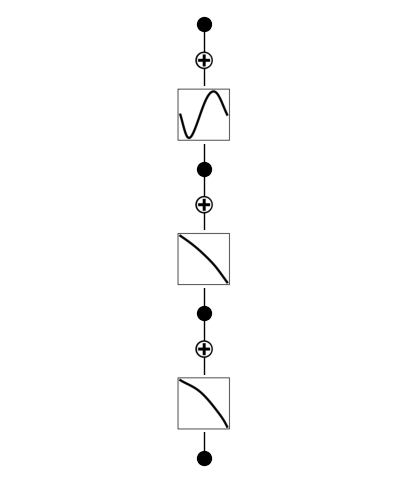

In [2]:
plot(model, train['x']);

with tricks

In [3]:
# create dataset f(x,y) = sin(pi*x). This task can be achieved by a [1,1] KAN
f = lambda x: torch.sin(torch.pi*x[:,[0]])
train, test = create_dataset(f, n_var=1, device=device)

# set base_fun to be linear
model = KANNetwork([1, 1, 1, 1], grid=5, k=3, seed=0, base_fun='identity', noise_scale=0.1, scale_base_mu=-1.0, scale_base_sigma=2.0, device=device)

# penality spline coefficients
history = fit(model, train, test, steps=20, lamb=1e-4, lamb_coef=10.0)
print('train RMSE', history['train/y'][-1] ** 0.5, 'test RMSE', history['val/y'][-1] ** 0.5)

train RMSE 0.009605156226346556 test RMSE 0.008845550092218622


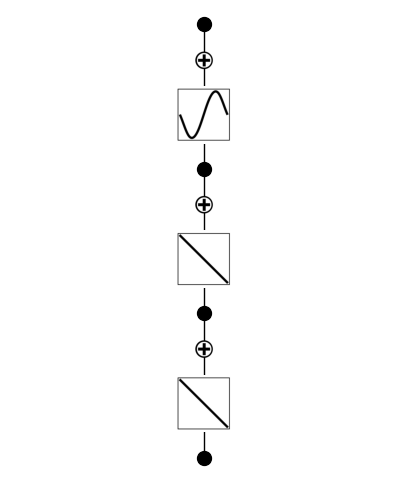

In [4]:
plot(model, train['x'], beta=10);